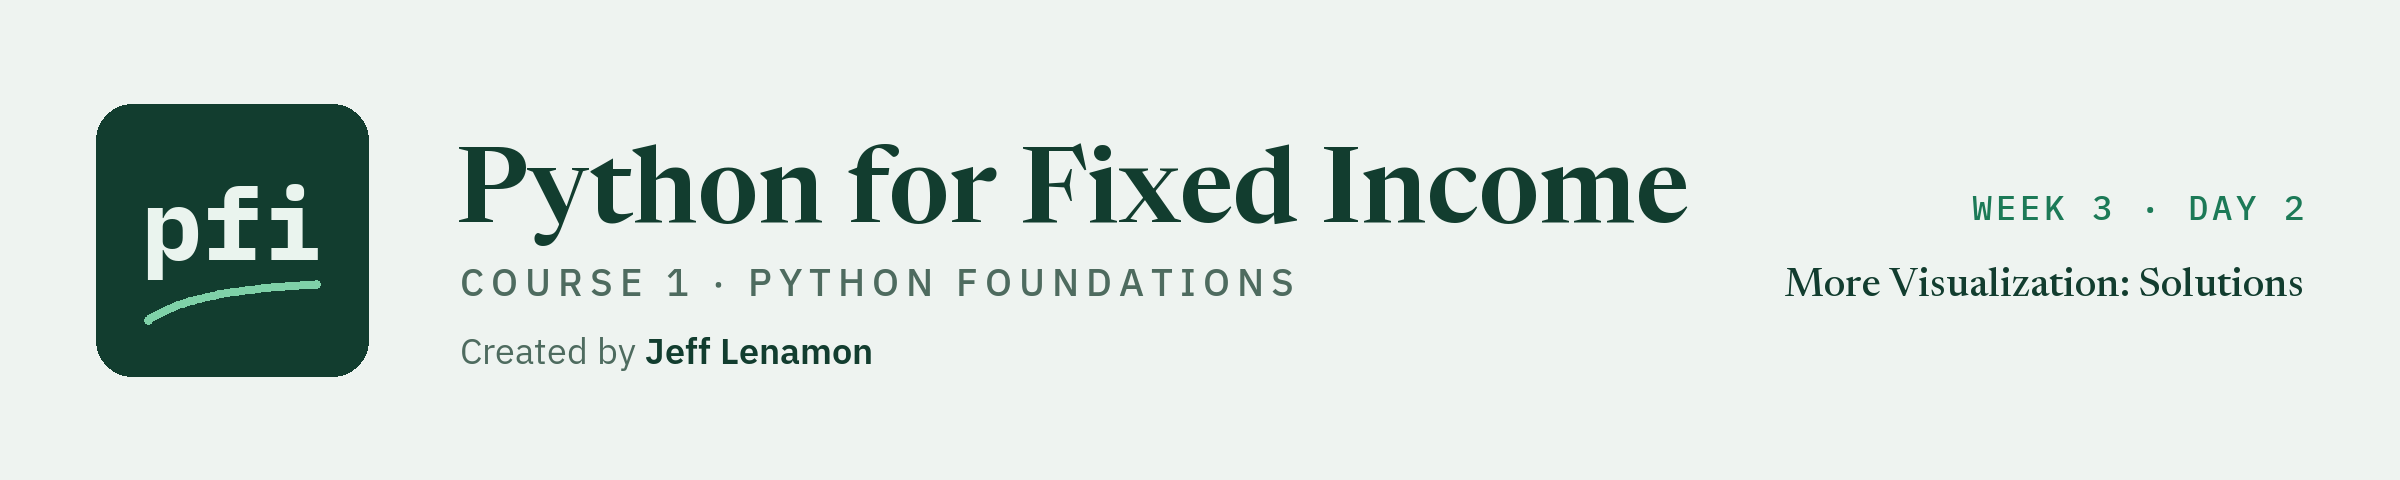

# More Visualization - Solutions

Week 3, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day2/12_visualization_more_solutions.ipynb)

## Exercises

These are the worked answers; the issuers are invented.
Run the next two cells first: the first defines `check`; the second reloads `book` and `bucket_order`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# fresh copies of the two tables, in Colab from GitHub, and today's chart settings
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
book = pd.merge(holdings, ratings, on='rating')
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
px.defaults.template = 'plotly_white'
px.defaults.color_discrete_sequence = ['#2E7D5B', '#9AA5B1']
print(book.shape)
print(bucket_order)

(200, 22)
['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']


### Exercise 1

Q. `score` numbers the ratings from 1 (AAA) to 18 (CCC). Fit `oas` on `score` with `np.polyfit()` and draw it with `sns.regplot()`. Store the slope and intercept, to 2 places, in **ex1_slope** and **ex1_intercept**.

Slope: 42.45 bp per rating notch
Intercept: -211.63 bp
R squared: 0.55
The line at score 1: -169.17 bp


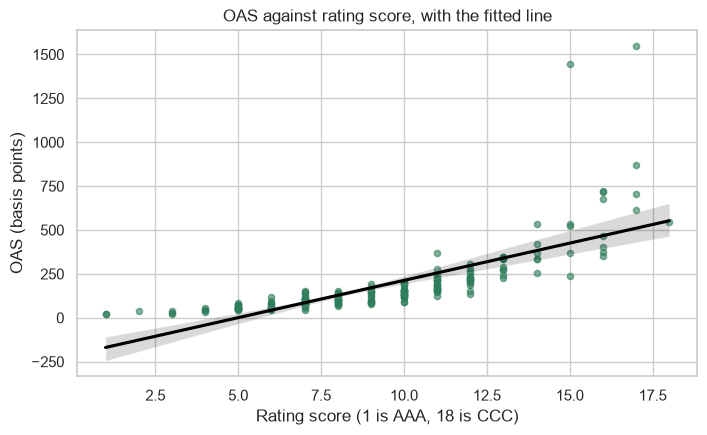

In [3]:
# x is the score and y is the OAS
slope, intercept = np.polyfit(book['score'], book['oas'], deg=1)
ex1_slope = round(slope, 2)
ex1_intercept = round(intercept, 2)

print('Slope:', ex1_slope, 'bp per rating notch')
print('Intercept:', ex1_intercept, 'bp')
print('R squared:', round(book['score'].corr(book['oas']) ** 2, 2))
print('The line at score 1:', round(intercept + slope * 1, 2), 'bp')

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=book, x='score', y='oas', seed=0,
            scatter_kws={'s': 20, 'alpha': 0.6}, line_kws={'color': 'black'}, ax=ax)
ax.set_title('OAS against rating score, with the fitted line')
ax.set_xlabel('Rating score (1 is AAA, 18 is CCC)')
ax.set_ylabel('OAS (basis points)')
plt.show()

The slope is 42.45 bp per rating notch and the intercept -211.63 bp, with R squared 0.55.
At score 1 the line gives a negative OAS, for a rating whose two bonds sit near 21 bp: Visualization's line plot rose slowly through the high ratings and steeply through the low ones, and one slope cannot do both.
The fit ran without complaint; the chart shows the points above the line at both ends and below it in the middle.

In [4]:
check('Exercise 1 slope', ex1_slope, 42.45)
check('Exercise 1 intercept', ex1_intercept, -211.63)

Exercise 1 slope: correct
Exercise 1 intercept: correct


### Exercise 2

Q. Draw `price` as a strip plot by bucket, in credit order, after `np.random.seed(0)`. Store the lowest price in **ex2_low** and its bucket in **ex2_bucket**; `idxmin()` gives the row label of the smallest value.

Lowest price: 62.045 in bucket B
           min      max
bucket                 
AAA     99.250  110.206
AA      89.614  119.131
A       76.903  118.201
BBB     73.873  117.164
BB      81.455  110.757
B       62.045  109.275
CCC     87.116  104.980


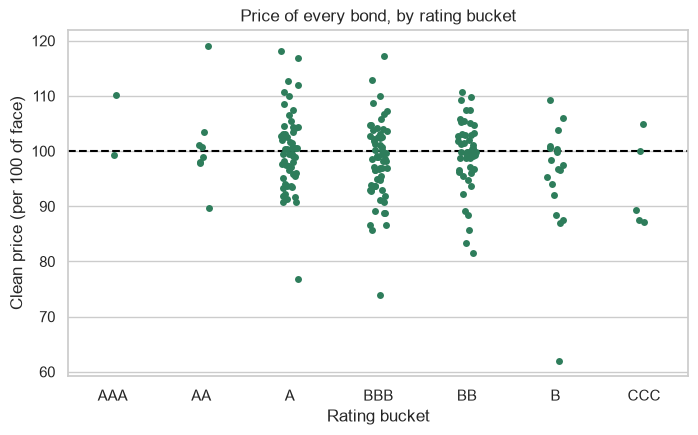

In [5]:
# the row with the lowest price
lowest = book.loc[book['price'].idxmin()]
ex2_low = lowest['price']
ex2_bucket = lowest['bucket']
print('Lowest price:', ex2_low, 'in bucket', ex2_bucket)
print(book.groupby('bucket')['price'].agg(['min', 'max']).loc[bucket_order])

# the same sideways nudges on every run
np.random.seed(0)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=book, x='bucket', y='price', order=bucket_order, ax=ax)
ax.axhline(100, color='black', linestyle='--')
ax.set_title('Price of every bond, by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Clean price (per 100 of face)')
plt.show()

The lowest price is 62.045, in the B bucket: the lowest dot on the chart, well below every other.
Every bucket has bonds on both sides of the dashed line at 100, AAA's two included.

In [6]:
check('Exercise 2 lowest price', ex2_low, 62.045)
check('Exercise 2 bucket', ex2_bucket, 'B')

Exercise 2 lowest price: correct
Exercise 2 bucket: correct


### Exercise 3

Q. Draw each sector's share of market value as flat bars, largest on top, with a percent axis and the value on each bar. Store the largest sector in **ex3_sector** and its share in percent, to 1 place, in **ex3_share**.

sector
Utilities          5.9
Technology         6.2
Energy             7.9
Health Care        7.9
Transportation     9.9
Industrials       10.7
Telecom           11.4
Consumer          11.5
Financials        13.9
Materials         14.6
Name: market_value, dtype: float64


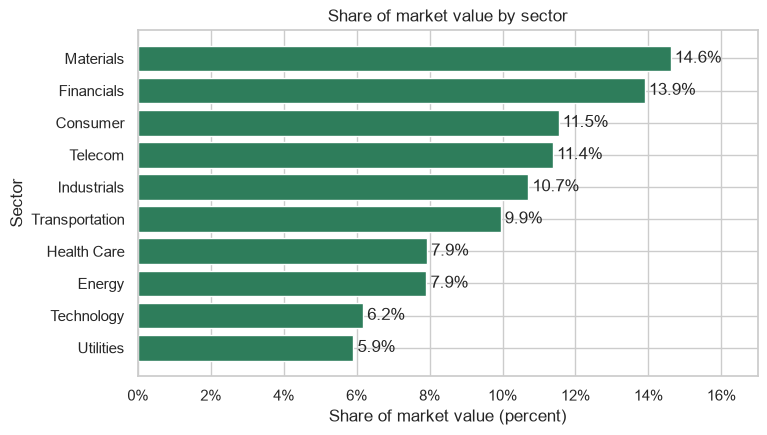

In [7]:
# each sector's market value as a percentage of the total, smallest first
value_by_sector = book.groupby('sector')['market_value'].sum()
share_by_sector = (value_by_sector / value_by_sector.sum() * 100).sort_values()
print(share_by_sector.round(1))
ex3_sector = share_by_sector.idxmax()
ex3_share = round(share_by_sector.max(), 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
# barh() draws from the bottom up, so the largest share, sorted last, is on top
bars = ax.barh(share_by_sector.index, share_by_sector.values)
# padding=3 sets each label 3 points clear of its bar
ax.bar_label(bars, fmt='%.1f%%', padding=3)
# the bars lie flat, so the percent format goes on the x axis
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xlim(0, 17)
ax.set_title('Share of market value by sector')
ax.set_xlabel('Share of market value (percent)')
ax.set_ylabel('Sector')
plt.show()

Materials has the largest share, 14.6 percent, then Financials at 13.9; Utilities is smallest at 5.9.
The order is Visualization's chart in millions: dividing every bar by one total changes the axis, not the picture.

In [8]:
check('Exercise 3 sector', ex3_sector, 'Materials')
check('Exercise 3 share', ex3_share, 14.6)

Exercise 3 sector: correct
Exercise 3 share: correct


### Exercise 4

Q. Draw a plotly scatter of `dts` against `duration` by grade, the issuer heading the hover box, ticker and rating inside. Point at the highest dot, then confirm with `idxmax()`: store its ticker in **ex4_ticker** and DTS in **ex4_dts**.

In [9]:
# the row with the highest DTS
top = book.loc[book['dts'].idxmax()]
ex4_ticker = top['ticker']
ex4_dts = top['dts']
print('Highest DTS:', ex4_ticker, top['issuer'], top['rating'],
      '- duration', top['duration'], 'years, OAS', top['oas'], 'bp')
print('Median DTS of the book:', book['dts'].median())

fig = px.scatter(book, x='duration', y='dts', color='grade', hover_name='issuer',
                 hover_data=['ticker', 'rating'],
                 labels={'duration': 'Duration (years)', 'dts': 'DTS (duration times spread)',
                         'grade': 'Grade'},
                 title='DTS against duration, one dot per bond')
fig.show()

Highest DTS: CLDB Calderby Retail B - duration 4.513 years, OAS 1446 bp
Median DTS of the book: 811.0


The highest dot is headed Calderby Retail, an invented issuer: CLDB, with a DTS of 6,525.8 at 4.513 years.
It is not a long bond: DTS is duration times spread, and this row has the second widest OAS in the file, 1,446 bp, against a median DTS of 811.0.

In [10]:
check('Exercise 4 ticker', ex4_ticker, 'CLDB')
check('Exercise 4 DTS', ex4_dts, 6525.8)

Exercise 4 ticker: correct
Exercise 4 DTS: correct


### Exercise 5

Q. Write `fitted_line_chart(x_column, y_column, x_label, y_label)`: it draws the bonds with the fitted line, a title and both labels, and returns the slope to 2 places. Store its slope for `dts` on `duration` in **ex5_dts_slope** and for `price` on `coupon` in **ex5_price_slope**.

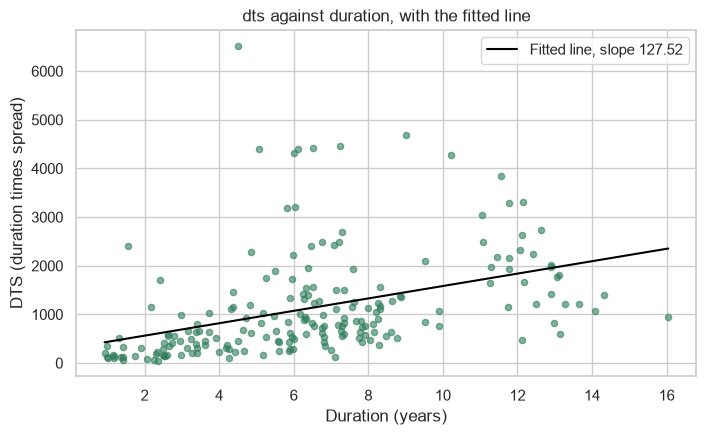

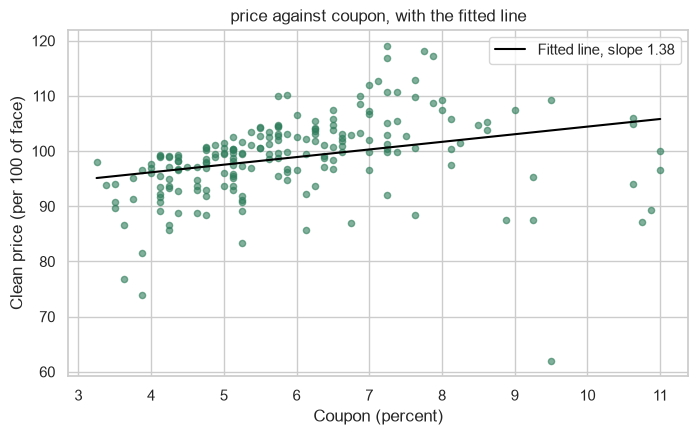

Slope of DTS on duration: 127.52 per year of duration
Slope of price on coupon: 1.38 points of price per point of coupon


In [11]:
def fitted_line_chart(x_column, y_column, x_label, y_label):
    """Draw y_column against x_column for the 200 bonds, with the fitted line. Return the slope."""
    # polyfit() takes x first and y second
    slope, intercept = np.polyfit(book[x_column], book[y_column], deg=1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.scatter(book[x_column], book[y_column], s=20, alpha=0.6)
    # the fitted line, from the lowest x in the book to the highest
    line_x = np.array([book[x_column].min(), book[x_column].max()])
    ax.plot(line_x, intercept + slope * line_x, color='black',
            label=f'Fitted line, slope {slope:,.2f}')
    ax.legend()
    ax.set_title(f'{y_column} against {x_column}, with the fitted line')
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.show()

    # float() turns the NumPy number into a plain one
    return round(float(slope), 2)


ex5_dts_slope = fitted_line_chart('duration', 'dts', 'Duration (years)',
                                  'DTS (duration times spread)')
ex5_price_slope = fitted_line_chart('coupon', 'price', 'Coupon (percent)',
                                    'Clean price (per 100 of face)')
print('Slope of DTS on duration:', ex5_dts_slope, 'per year of duration')
print('Slope of price on coupon:', ex5_price_slope, 'points of price per point of coupon')

Each extra year of duration goes with 127.52 more DTS, and each extra point of coupon with 1.38 more points of price.
The fit, the line, and the labels are written once, inside the function: a third pair of columns is one more line.
Returning the slope lets it be stored and checked; both clouds are loose, so look at the charts before quoting either.

In [12]:
check('Exercise 5 slope of DTS on duration', ex5_dts_slope, 127.52)
check('Exercise 5 slope of price on coupon', ex5_price_slope, 1.38)

Exercise 5 slope of DTS on duration: correct
Exercise 5 slope of price on coupon: correct


### Exercise 6

Q. Fit `yield_pct` on `coupon` for each grade on its own, and draw the grades in two panels with `sns.lmplot(col='grade', ci=None)`. Store the slopes, to 2 places, in **ex6_ig_slope** and **ex6_hy_slope**.

Investment Grade slope: 0.2 points of yield per point of coupon
High Yield slope: 1.11 points of yield per point of coupon


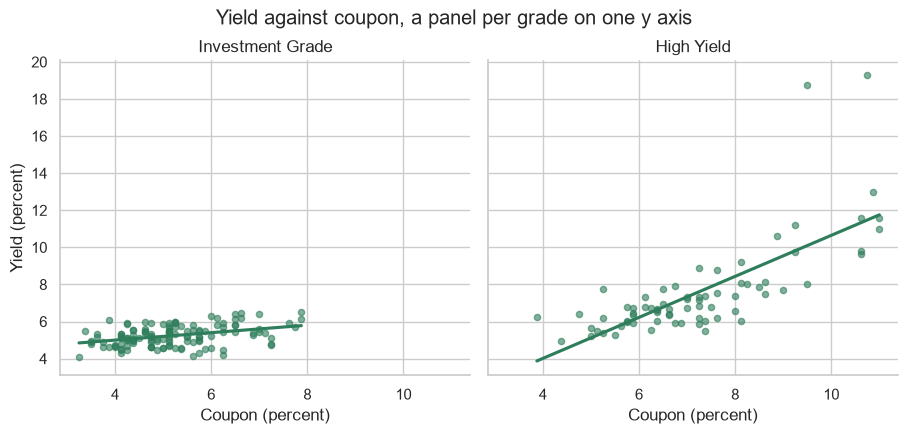

In [13]:
# one fit per grade, on that grade's bonds only
slopes = {}
for grade in ['Investment Grade', 'High Yield']:
    part = book[book['grade'] == grade]
    slopes[grade] = np.polyfit(part['coupon'], part['yield_pct'], deg=1)[0]
ex6_ig_slope = round(slopes['Investment Grade'], 2)
ex6_hy_slope = round(slopes['High Yield'], 2)
print('Investment Grade slope:', ex6_ig_slope, 'points of yield per point of coupon')
print('High Yield slope:', ex6_hy_slope, 'points of yield per point of coupon')

grid = sns.lmplot(data=book, x='coupon', y='yield_pct', col='grade', ci=None,
                  height=4.2, aspect=1.1,
                  scatter_kws={'s': 20, 'alpha': 0.6})
grid.set_axis_labels('Coupon (percent)', 'Yield (percent)')
grid.set_titles('{col_name}')
grid.figure.suptitle('Yield against coupon, a panel per grade on one y axis', y=1.03)
plt.show()

The slope is 0.2 for Investment Grade and 1.11 for High Yield; the book's 0.88 sits between them and describes neither.
Within Investment Grade the line is nearly flat; within High Yield one more point of coupon goes with a little over one point of yield.

In [14]:
check('Exercise 6 Investment Grade slope', ex6_ig_slope, 0.2)
check('Exercise 6 High Yield slope', ex6_hy_slope, 1.11)

Exercise 6 Investment Grade slope: correct
Exercise 6 High Yield slope: correct


### Exercise 7: AI check

You ask an AI assistant to fit yield on coupon across the book and draw the line over the bonds.

Its code, written for this course in an AI's style, has one bug.

Q. Before you run it: what slope should it find? Section 12.2 worked it out. Then run it.

Section 12.2's slope is 0.88; the original code stored 0.63, with no error, and drew a line that looked reasonable.
`np.polyfit()` takes x first and y second, and the code passed the yield first: it fitted coupon on yield, 0.63 points of coupon per point of yield, then drew that line with coupon along the x axis.
The two slopes are not one number turned over: 1 / 0.63 is about 1.6, and 0.88 x 0.63 is 0.55, R squared; they agree only when every point is on the line.
Excel's `=SLOPE(known_ys, known_xs)` takes y first, the other order, so the slip is an easy one; one number worked out earlier caught it.

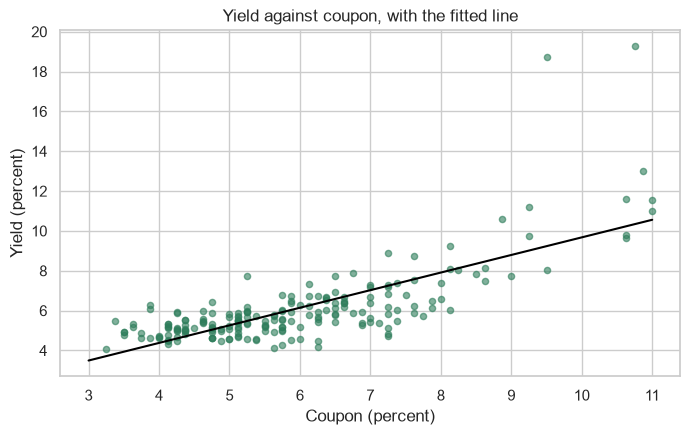

In [15]:
# straight-line fit of yield on coupon: x is the coupon and y is the yield
slope, intercept = np.polyfit(book['coupon'], book['yield_pct'], 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(book['coupon'], book['yield_pct'], s=20, alpha=0.6)

# the fitted line between a coupon of 3 percent and 11 percent
line_x = np.array([3, 11])
ax.plot(line_x, intercept + slope * line_x, color='black')

ax.set_title('Yield against coupon, with the fitted line')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Yield (percent)')

plt.show()

ex7_slope = round(slope, 2)

In [16]:
check('Exercise 7 slope', ex7_slope, 0.88)

Exercise 7 slope: correct
